# Machine Learning #08 — Attention Mechanisms 🎯


The **attention mechanism** is the single most important idea in modern deep learning —
it powers translation systems, speech recognition and every large language model you have
ever used. The good news: the core idea fits into **three lines of tensor code**.

Today's workflow:

> **hidden states → scores → softmax weights → weighted sum (context) → prediction**

## Imports and setup

Remember to set **GPU** runtime in Colab! (Everything also runs on CPU in a few minutes.)

In [ ]:
!pip install torchinfo

In [1]:
import re
import time
from collections import Counter

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

import torchinfo

from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110})

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch version:", torch.__version__)
print("device:", device)

torch version: 2.6.0+cu124
device: cuda


# 1. Why attention? 🧠

Think about the everyday meaning of the word **attention**: out of everything around you,
you *select* the few things that matter right now and ignore the rest.
A neural network can do exactly the same with its inputs.

### The problem with recurrent networks 🔎

An LSTM reads a sequence step by step and keeps a **hidden state** $h_t$.
If we only use the **last** hidden state $h_T$ for the prediction, then:

- the whole sequence — no matter how long — must be squeezed into **one fixed-size vector**,
- information from the **beginning** of the sequence has to survive dozens of update steps
  (the classic "forgetting" problem),
- every position contributes to the prediction **implicitly**; we cannot tell which word
  actually mattered.

> 💡 A single vector as the summary of a 200-word review is a real **information bottleneck**.

### The idea 💡

Instead of throwing away $h_1, \dots, h_{T-1}$, we keep **all** hidden states and build the
summary as a **weighted sum**:

$$c \;=\; \sum_{t=1}^{T} \alpha_t \, h_t$$

where the weights $\alpha_t$ are:

- **non-negative** and **sum to one** ($\sum_t \alpha_t = 1$) — because they come from a **softmax**,
- **learned** — the network decides by itself what is important,
- **readable by us** — a large $\alpha_t$ means "position $t$ mattered for this prediction". 🔍

### How are the weights computed?

In two steps:

1. **Score** every position with a small learnable function: $e_t = \text{score}(h_t)$
2. **Normalise** the scores into a probability distribution:

$$\alpha_t \;=\; \frac{\exp(e_t)}{\sum_{k=1}^{T}\exp(e_k)} \;=\; \text{softmax}(e)_t$$

That is it. The rest of this notebook is that formula, over and over again. 🙂

> 🔎 **Question:** which real-world tasks would benefit the most from attention?
> Think about translation, medical time series, anomaly detection in sensor data...

# 2. Attention by hand ✋

Before we train anything, let's compute attention **manually** on a tiny example.

Imagine a 4-token sentence that has already been processed by an LSTM with **3 hidden units**.
The result is a matrix of hidden states $H$ with shape `(batch=1, time=4, hidden=3)`.

In [2]:
tokens = ["the", "food", "was", "terrible"]

# Hidden states H: (batch, time, hidden) - here we simply invent them
H_demo = torch.tensor([[
    [0.1, 0.0, 0.2],   # "the"       - a boring function word
    [0.7, 0.2, 0.1],   # "food"      - topic of the sentence
    [0.0, 0.1, 0.1],   # "was"       - boring again
    [0.9, 0.8, 0.3],   # "terrible"  - carries the sentiment
]])

print("H shape (batch, time, hidden):", H_demo.shape)
H_demo

H shape (batch, time, hidden): torch.Size([1, 4, 3])


tensor([[[0.1000, 0.0000, 0.2000],
         [0.7000, 0.2000, 0.1000],
         [0.0000, 0.1000, 0.1000],
         [0.9000, 0.8000, 0.3000]]])

### Step 1 — score every position

For now we use the simplest possible scoring function: a **dot product with a learnable
vector** $w$ (we just pick the numbers here, in a real model they are trained):

$$e_t = h_t \cdot w$$

In [3]:
w = torch.tensor([1.0, 2.0, 0.0])          # "importance direction" in hidden space

scores = H_demo @ w                        # (1, 4, 3) @ (3,) -> (1, 4)
print("scores shape:", scores.shape)

for tok, s in zip(tokens, scores[0]):
    print(f"  {tok:>9s}: {s.item():5.2f}")

scores shape: torch.Size([1, 4])
        the:  0.10
       food:  1.10
        was:  0.20
   terrible:  2.50


### Step 2 — softmax turns scores into weights

Softmax makes the scores **positive** and makes them **sum to 1**, so they can be read as
"how much percent of my attention goes here".

In [4]:
alpha = torch.softmax(scores, dim=1)       # normalise over the TIME axis!

for tok, a in zip(tokens, alpha[0]):
    print(f"  {tok:>9s}: {a.item():.3f}")

print("\nSum of the weights:", alpha.sum().item())   # must be exactly 1.0

        the: 0.063
       food: 0.172
        was: 0.070
   terrible: 0.696

Sum of the weights: 1.0


> ⚠️ Note `dim=1`: we normalise over **time**, not over the hidden units.
> A softmax over the wrong axis is one of the most common attention bugs.

### Step 3 — the context vector

$$c = \sum_t \alpha_t h_t$$

In tensor form this is a **batched matrix multiplication**: `(1, 1, 4) @ (1, 4, 3) -> (1, 1, 3)`.

In [5]:
context = torch.bmm(alpha.unsqueeze(1), H_demo).squeeze(1)   # (1, 3)

print("context vector      :", context[0].tolist())
print("simple mean pooling :", H_demo.mean(dim=1)[0].tolist())
print("last hidden state   :", H_demo[:, -1, :][0].tolist())

context vector      : [0.7524411678314209, 0.5977748036384583, 0.24543379247188568]
simple mean pooling : [0.42500001192092896, 0.2750000059604645, 0.17500001192092896]
last hidden state   : [0.8999999761581421, 0.800000011920929, 0.30000001192092896]


Compare the three rows above:

- **mean pooling** treats `"the"` and `"terrible"` as equally important,
- the **last hidden state** happens to work here, but only because the important word is last,
- the **context vector** is pulled towards the informative tokens — *by design*.

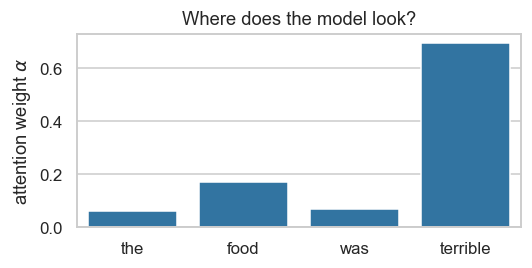

In [6]:
plt.figure(figsize=(5, 2.6))
sns.barplot(x=tokens, y=alpha[0].numpy(), color="tab:blue")
plt.ylabel(r"attention weight $\alpha$")
plt.title("Where does the model look?")
plt.tight_layout()
plt.show()

> 💡 **The whole mechanism is three lines:** `scores -> softmax -> weighted sum`.
> Everything that follows only changes **how the scores are computed** and **who asks
> the question**.

In a real model we do **not** invent the vector `w` — we let the network **learn** it.
That is exactly what we do next.

# 3. Task 1: Find-Max 🔢

A toy task that is perfect for **seeing** attention at work.

- **Input:** a sequence of 15 random numbers from the interval $[0, 10)$
- **Output:** the **maximum** of the sequence (a single number → **regression**)

Why this task? Because we know exactly **where the model should look** — at the position of
the maximum. So we can check whether the attention weights point there. 🔍

In [7]:
def make_sequences(n_samples, seq_len=15, generator=None):
    X = torch.rand(n_samples, seq_len, 1, generator=generator) * 10.0
    y = X.max(dim=1).values
    return X, y

In [8]:
SEQ_LEN = 15
g = torch.Generator().manual_seed(SEED)

X_train, y_train = make_sequences(6000, SEQ_LEN, g)  
X_val,   y_val   = make_sequences(1000, SEQ_LEN, g)
X_test,  y_test  = make_sequences(1000, SEQ_LEN, g)

print("train:", X_train.shape, y_train.shape)
print("val  :", X_val.shape,   y_val.shape)
print("test :", X_test.shape,  y_test.shape)

train: torch.Size([6000, 15, 1]) torch.Size([6000, 1])
val  : torch.Size([1000, 15, 1]) torch.Size([1000, 1])
test : torch.Size([1000, 15, 1]) torch.Size([1000, 1])


In [9]:
# One example: the sequence and its maximum
print("sequence:", X_train[0].squeeze(-1).numpy().round(2))
print(f"maximum : {y_train[0].item():.2f} at position {X_train[0].argmax().item()}")

sequence: [8.82 9.15 3.83 9.59 3.9  6.01 2.57 7.94 9.41 1.33 9.35 5.94 8.69 5.68
 7.41]
maximum : 9.59 at position 3


### Mini-batches with `DataLoader` 📦

In [10]:
BATCH_SIZE = 64

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val,   y_val),   batch_size=256)

xb, yb = next(iter(train_loader))
print("one batch:", xb.shape, yb.shape)
print("batches per epoch:", len(train_loader))

one batch: torch.Size([64, 15, 1]) torch.Size([64, 1])
batches per epoch: 94


## The attention layer ⚙️

We implement **additive attention** (also called *Bahdanau attention*). The scoring function is a tiny one-hidden-layer network:

$$e_t \;=\; v^\top \tanh\!\big(W h_t + b\big)$$

$$\alpha \;=\; \text{softmax}(e), \qquad c \;=\; \sum_t \alpha_t h_t$$

- $W$ projects the hidden state into a small **attention space** (`attn_units`),
- $\tanh$ adds a non-linearity, so the score can be a non-trivial function of $h_t$,
- $v$ collapses the result into **one number per time step**.

Two implementation details worth noticing:

- `masked_fill(~mask, -inf)` — positions we want to **forbid** get a score of $-\infty$,
  which softmax turns into a weight of exactly **0**. We will need this in Part 4.
- `forward()` returns **both** the context **and** the weights. In PyTorch we simply return
  whatever we want from `forward()` — no tricks are needed to look inside the model. 🎉

In [11]:
class AdditiveAttention(nn.Module):
    def __init__(self, hidden_size, attn_units=32):
        super().__init__()
        self.W = nn.Linear(hidden_size, attn_units)      # hidden -> attention space
        self.v = nn.Linear(attn_units, 1, bias=False)    # attention space -> one score

    def forward(self, H, mask=None):
        # H: (batch, time, hidden), mask: (batch, time) with True = real token
        scores = self.v(torch.tanh(self.W(H)))           # (batch, time, 1)
        scores = scores.squeeze(-1)                      # (batch, time)

        if mask is not None:
            scores = scores.masked_fill(~mask, float("-inf"))   # forbidden -> weight 0

        weights = torch.softmax(scores, dim=1)           # (batch, time), sums to 1
        context = torch.bmm(weights.unsqueeze(1), H)     # (batch, 1, hidden)
        context = context.squeeze(1)                     # (batch, hidden)
        return context, weights

In [12]:
# Quick shape check on random data - always do this before training!
att_test = AdditiveAttention(hidden_size=64, attn_units=32)
ctx, wts = att_test(torch.randn(8, 15, 64))

print("context:", ctx.shape, "| weights:", wts.shape)
print("each row of weights sums to 1:", torch.allclose(wts.sum(dim=1), torch.ones(8)))

context: torch.Size([8, 64]) | weights: torch.Size([8, 15])
each row of weights sums to 1: True


## The model 🏗️

$$\text{sequence} \rightarrow \text{LSTM (all 64-dim hidden states)} \rightarrow \text{attention} \rightarrow \text{context} \rightarrow \text{Linear} \rightarrow \hat{y}$$

- `nn.LSTM(..., batch_first=True)` makes the tensors `(batch, time, features)` — the same
  ordering we used above. Without it PyTorch expects `(time, batch, features)`. ⚠️
- The LSTM returns **all** hidden states `H` (that is what we need!) plus the final states.
- The output layer has **no activation** — this is regression, we predict a raw number.

In [13]:
class FindMaxNet(nn.Module):
    def __init__(self, hidden_size=64, attn_units=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.attention = AdditiveAttention(hidden_size, attn_units)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        H, (h_n, c_n) = self.lstm(x)            # H: (batch, time, hidden)
        context, weights = self.attention(H)    # context: (batch, hidden)
        out = self.head(context)                # (batch, 1)
        return out, weights                     # we return the weights for visualisation

In [14]:
model_max = FindMaxNet().to(device)
print(model_max)

FindMaxNet(
  (lstm): LSTM(1, 64, batch_first=True)
  (attention): AdditiveAttention(
    (W): Linear(in_features=64, out_features=32, bias=True)
    (v): Linear(in_features=32, out_features=1, bias=False)
  )
  (head): Linear(in_features=64, out_features=1, bias=True)
)


In [15]:
torchinfo.summary(model_max, input_size=(BATCH_SIZE, SEQ_LEN, 1))

Layer (type:depth-idx)                   Output Shape              Param #
FindMaxNet                               [64, 1]                   --
├─LSTM: 1-1                              [64, 15, 64]              17,152
├─AdditiveAttention: 1-2                 [64, 64]                  --
│    └─Linear: 2-1                       [64, 15, 32]              2,080
│    └─Linear: 2-2                       [64, 15, 1]               32
├─Linear: 1-3                            [64, 1]                   65
Total params: 19,329
Trainable params: 19,329
Non-trainable params: 0
Total mult-adds (M): 16.61
Input size (MB): 0.00
Forward/backward pass size (MB): 0.75
Params size (MB): 0.08
Estimated Total Size (MB): 0.83

## Training 🚀
Loss: **MSE** (mean squared error), the standard choice for regression.

In [ ]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_max.parameters(), lr=2e-3)

EPOCHS = 80
history = {"train_loss": [], "val_loss": []}

start = time.time()
for epoch in range(EPOCHS):
    # ---- training -------------------------------------------------
    model_max.train()
    running = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        preds, _ = model_max(xb)          # forward
        loss = criterion(preds, yb)       # loss

        optimizer.zero_grad()             # reset gradients
        loss.backward()                   # backward
        optimizer.step()                  # update

        running += loss.item() * xb.size(0)
    train_loss = running / len(train_loader.dataset)

    # ---- validation (no gradients!) -------------------------------
    model_max.eval()
    running = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            preds, _ = model_max(xb)
            running += criterion(preds, yb).item() * xb.size(0)
    val_loss = running / len(val_loader.dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch+1:3d} | train MSE {train_loss:.4f} | val MSE {val_loss:.4f}")

print(f"\nTraining finished.")

epoch  10 | train MSE 0.3342 | val MSE 0.3700
epoch  20 | train MSE 0.0800 | val MSE 0.0773
epoch  30 | train MSE 0.0555 | val MSE 0.0510
epoch  40 | train MSE 0.0338 | val MSE 0.0310
epoch  50 | train MSE 0.0221 | val MSE 0.0253
epoch  60 | train MSE 0.0175 | val MSE 0.0147
epoch  70 | train MSE 0.0116 | val MSE 0.0099
epoch  80 | train MSE 0.0072 | val MSE 0.0089

Training finished in 14.6 s


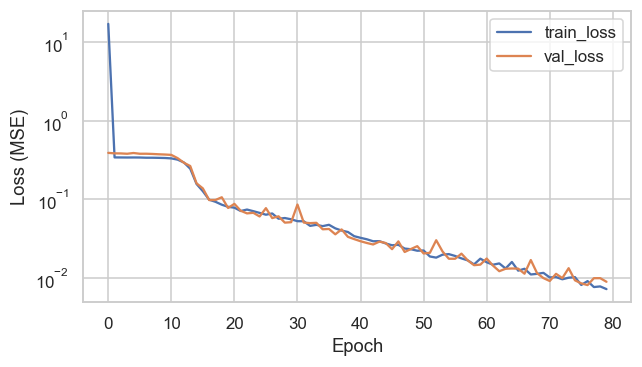

In [18]:
plt.figure(figsize=(6, 3.5))
for key, values in history.items():
    plt.plot(values, label=key)

plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.yscale("log")           # log scale - the loss drops over orders of magnitude
plt.legend()
plt.tight_layout()
plt.show()

## Evaluation 📊

First the numbers, then the picture.

In [19]:
model_max.eval()
with torch.no_grad():
    test_preds, test_weights = model_max(X_test.to(device))

test_preds   = test_preds.cpu()
test_weights = test_weights.cpu()

mse = criterion(test_preds, y_test).item()
mae = (test_preds - y_test).abs().mean().item()
print(f"Test MSE: {mse:.4f}")
print(f"Test MAE: {mae:.4f}   (average error in the original units)")

Test MSE: 0.0104
Test MAE: 0.0674   (average error in the original units)


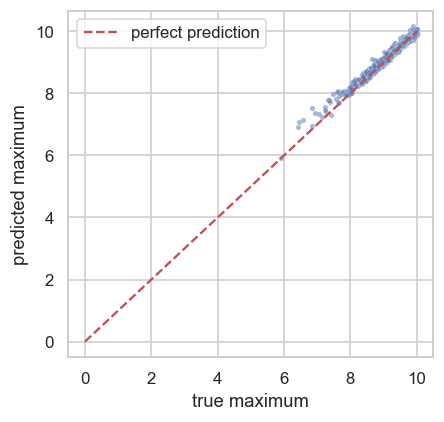

In [20]:
plt.figure(figsize=(4.2, 4))
sns.scatterplot(x=y_test.squeeze(-1).numpy(), y=test_preds.squeeze(-1).numpy(), s=12, alpha=.5)
plt.plot([0, 10], [0, 10], "r--", label="perfect prediction")
plt.xlabel("true maximum"); plt.ylabel("predicted maximum")
plt.legend(); plt.tight_layout(); plt.show()

### Does the attention really look at the maximum? 🔍

This is the interesting part. For every test sequence we compare:

- `argmax` of the **sequence** — where the true maximum is,
- `argmax` of the **attention weights** — where the model looked.

In [21]:
true_pos = X_test.squeeze(-1).argmax(dim=1)
att_pos  = test_weights.argmax(dim=1)

exact  = (att_pos == true_pos).float().mean().item()
within = ((att_pos - true_pos).abs() <= 1).float().mean().item()

print(f"Attention peak exactly on the maximum : {exact:.1%}")
print(f"Attention peak within +/- 1 position  : {within:.1%}")

Attention peak exactly on the maximum : 76.4%
Attention peak within +/- 1 position  : 85.7%


Nobody told the model *"look at the largest number"* — there is no such term in the loss
function. It only ever saw pairs (sequence, its maximum) and **discovered the strategy on its own**. 🤯

Let's plot 6 different test sequences. Blue = the values, red = the attention weights
(rescaled so that both fit in one plot).

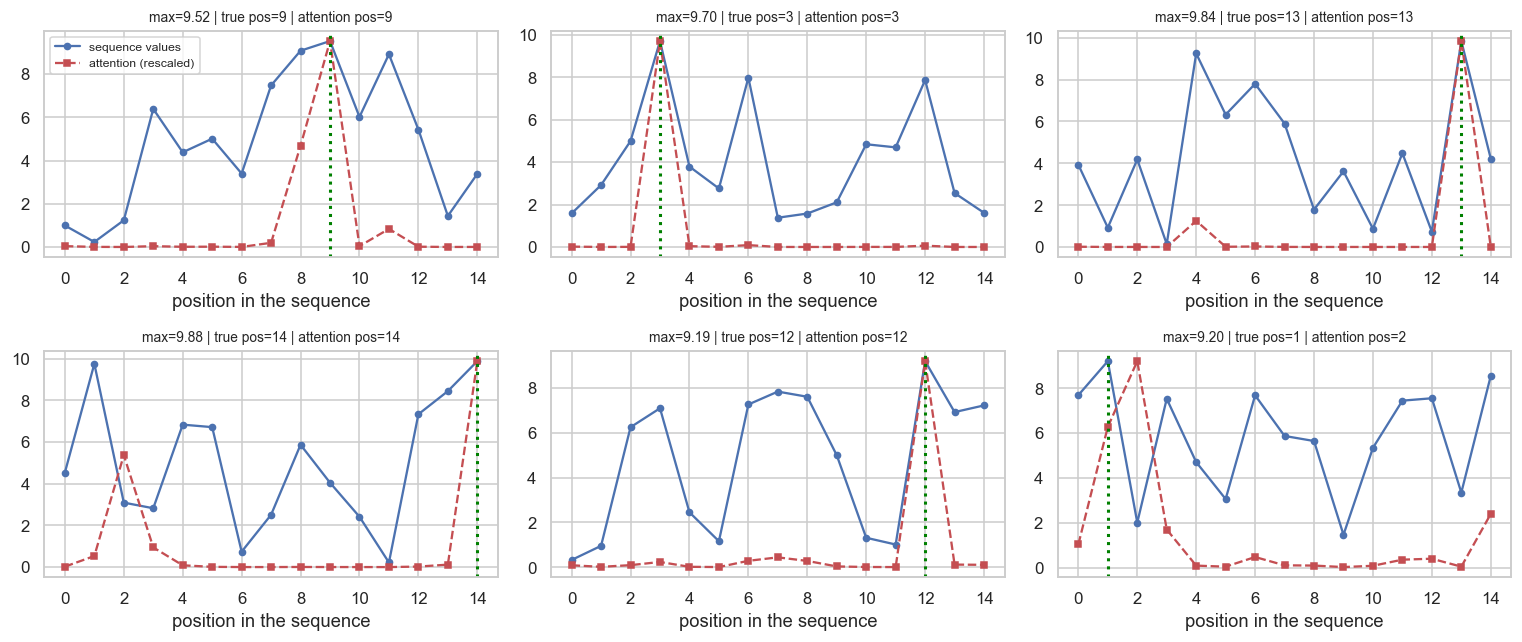

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))

for i, ax in enumerate(axes.ravel()):
    seq = X_test[i].squeeze(-1).numpy()
    att = test_weights[i].numpy()

    ax.plot(seq, "b-o", ms=4, label="sequence values")
    ax.plot(att * seq.max() / max(att.max(), 1e-9), "r--s", ms=4, label="attention (rescaled)")
    ax.axvline(seq.argmax(), color="green", ls=":", lw=2)

    ax.set_title(f"max={y_test[i].item():.2f} | true pos={seq.argmax()} | attention pos={att.argmax()}",
                 fontsize=9)
    ax.set_xlabel("position in the sequence")
    if i == 0:
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

> 💡 The maximum sits at a **different position** in every sequence, and the red curve follows
> it. That is the proof that the model **generalised** the task instead of memorising something
> silly like *"the answer is always the 5th number"*.


# 4. Task B: Sentiment analysis 💬

Now something real. We classify **short customer reviews** (restaurants, products, films) as
**positive (1)** or **negative (0)**. Each review is a single sentence, which is exactly the
kind of data where every word counts.

We will train **two models** and compare them:

| Model | Sequence summary |
|---|---|
| **Baseline** | the **last** hidden state of the LSTM |
| **Attention** | a **weighted sum** of all hidden states |

Everything else stays identical, so any difference comes from the attention layer alone.
And as a bonus we will be able to see **which words** the model based its decision on. 🔍

In [26]:
url = "https://raw.githubusercontent.com/rasvob/VSB-FEI-Deep-Learning-Exercises/main/datasets/yelp_labelled.txt"
path = "yelp_labelled.txt"

import urllib.request
urllib.request.urlretrieve(url, path)

# each line is:  <review text> \t <label 0/1>
lines = [ln for ln in open(path, encoding="utf-8").read().splitlines() if ln.strip()]
rows = []
for ln in lines:
    parts = ln.rsplit("\t", 1)          # split on the LAST tab -> robust
    if len(parts) != 2:
        continue
    text, label = parts
    if label.strip() not in ("0", "1"):
        continue
    rows.append({"Text": text.strip(), "Label": int(label)})

df = pd.DataFrame(rows)
print("rows:", len(df))
df.head()

rows: 3000


,Text,Label
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


In [29]:
print(df.Label.value_counts())
print("\nA positive one:", df[df.Label == 1].Text.iloc[0])
print("A negative one:", df[df.Label == 0].Text.iloc[0])

Label
1    1500
0    1500
Name: count, dtype: int64

A positive one: Wow... Loved this place.
A negative one: Crust is not good.


> 💡 The dataset is **balanced** (50 % / 50 %), so plain **accuracy** is a fair metric here.
> We still use `stratify` in the split to keep it balanced in every subset.

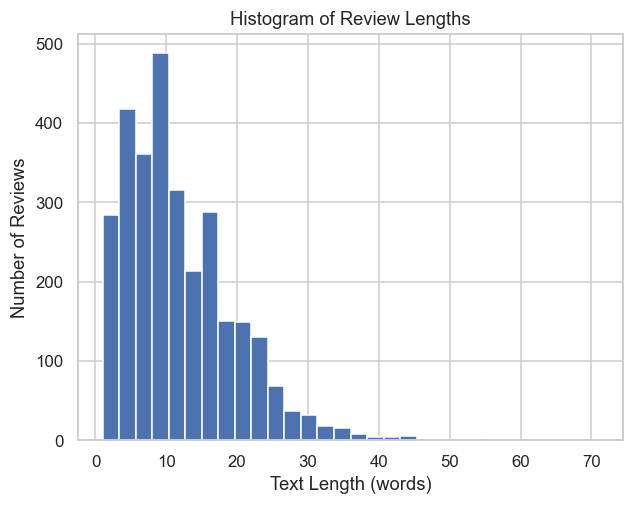

In [32]:
df["Text_length"] = df["Text"].str.split().str.len()

plt.hist(df.Text.str.split().str.len(), bins=30)
plt.xlabel("Text Length (words)")
plt.ylabel("Number of Reviews")
plt.title("Histogram of Review Lengths")
plt.show()

## From text to tensors 🔤

A network cannot read strings. The pipeline is always the same:

1. **Tokenisation** — split the text into words (we lowercase and drop punctuation),
2. **Vocabulary** — map each word to an integer id; keep only the most frequent `MAX_TOKENS`,
3. **Encoding + padding** — turn each review into a fixed-length vector of ids.

Two special ids are reserved:

| id | token | meaning |
|---|---|---|
| `0` | `<pad>` | filler, so that all reviews have the same length |
| `1` | `<unk>` | any word that is not in the vocabulary |

> ⚠️ The vocabulary is built from the **training set only**. Building it from all the data
> would leak information from the test set into training.

In [30]:
def tokenize(text):
    '''Lowercase the text and keep sequences of letters/digits/apostrophes.'''
    return re.findall(r"[a-z0-9']+", text.lower())


print(tokenize("The food was GREAT, but the service wasn't..."))

['the', 'food', 'was', 'great', 'but', 'the', 'service', "wasn't"]


In [34]:
X_temp, X_test, y_temp, y_test = train_test_split(
    df.Text.values, df.Label.values,
    test_size=0.15, random_state=SEED, stratify=df.Label.values,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1765, random_state=SEED, stratify=y_temp,   # 0.1765 * 0.85 = 0.15
)

print(f"train: {len(X_train)} | val: {len(X_val)} | test: {len(X_test)}")

train: 2099 | val: 451 | test: 450


In [35]:
MAX_TOKENS = 3000     # vocabulary size
MAX_LEN    = 32  
PAD_ID, UNK_ID = 0, 1

counter = Counter(tok for text in X_train for tok in tokenize(text))

itos = ["<pad>", "<unk>"] + [w for w, _ in counter.most_common(MAX_TOKENS - 2)]  # id -> word
stoi = {w: i for i, w in enumerate(itos)}                                        # word -> id

print("vocabulary size:", len(itos))
print("most frequent words:", itos[2:12])

vocabulary size: 3000
most frequent words: ['the', 'and', 'i', 'a', 'is', 'to', 'it', 'this', 'of', 'was']


In [36]:
def encode(texts):
    '''Text -> tensor of ids of shape (n_texts, MAX_LEN), padded with PAD_ID.'''
    out = torch.full((len(texts), MAX_LEN), PAD_ID, dtype=torch.long)
    for i, text in enumerate(texts):
        ids = [stoi.get(tok, UNK_ID) for tok in tokenize(text)][:MAX_LEN]   # truncate
        out[i, :len(ids)] = torch.tensor(ids, dtype=torch.long)             # the rest stays <pad>
    return out


X_tr, X_va, X_te = encode(X_train), encode(X_val), encode(X_test)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

print("X_tr:", X_tr.shape, "| y_tr:", y_train_tensor.shape)

X_tr: torch.Size([2099, 32]) | y_tr: torch.Size([2099, 1])


In [37]:
# What one review looks like after encoding
print("original :", X_train[0])
print("ids      :", X_tr[0].tolist())
print("decoded  :", " ".join(itos[i] for i in X_tr[0].tolist()))
avg_len = (X_tr != PAD_ID).float().sum(1).mean().item()
print(f"\nreal tokens per review (average): {avg_len:.1f} out of {MAX_LEN}")

original : This totally UNfunny movie is so over the top and pathetic and unrealistic that throughout the whole 90 minutes of utter torture I probably looked at my watch about 70000 times!
ids      : [9, 309, 1138, 27, 6, 26, 134, 2, 492, 3, 839, 3, 1747, 14, 1139, 2, 424, 1140, 135, 10, 1748, 674, 4, 197, 675, 34, 17, 210, 56, 1749, 244, 0]
decoded  : this totally unfunny movie is so over the top and pathetic and unrealistic that throughout the whole 90 minutes of utter torture i probably looked at my watch about 70000 times <pad>

real tokens per review (average): 11.6 out of 32


> 🔎 Look at the decoded review: more than half of the positions are `<pad>`.

In [38]:
train_loader_txt = DataLoader(TensorDataset(X_tr, y_train_tensor), batch_size=32, shuffle=True)
val_loader_txt   = DataLoader(TensorDataset(X_va, y_val_tensor), batch_size=128)

## Baseline: LSTM without attention

$$\text{ids} \rightarrow \text{Embedding} \rightarrow \text{LSTM} \rightarrow h_T \rightarrow \text{Dropout} \rightarrow \text{Linear} \rightarrow \text{logit}$$

- **`nn.Embedding(vocab, dim, padding_idx=0)`** is a lookup table: every word id gets its own
  trainable vector. Words used in similar contexts end up close together in this space.
  `padding_idx=0` keeps the `<pad>` vector fixed at zero.
- We take `h_n[-1]` — the hidden state after the **last** time step.
- The output is a single **logit**; we use **`BCEWithLogitsLoss`** exactly as in Exercise #01.

In [39]:
EMB_DIM, HID_DIM = 64, 64

class BaselineLSTM(nn.Module):
    def __init__(self, vocab_size, emb_dim=EMB_DIM, hidden_size=HID_DIM):
        super().__init__()
        self.emb  = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        self.lstm = nn.LSTM(emb_dim, hidden_size, batch_first=True)
        self.drop = nn.Dropout(0.3)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        H, (h_n, c_n) = self.lstm(self.emb(x))
        summary = h_n[-1]                 # (batch, hidden) - the LAST hidden state only
        return self.head(self.drop(summary))

In [40]:
torch.manual_seed(SEED)
model_base = BaselineLSTM(len(itos)).to(device)
torchinfo.summary(model_base, input_data=X_tr[:32].to(device))

Layer (type:depth-idx)                   Output Shape              Param #
BaselineLSTM                             [32, 1]                   --
├─Embedding: 1-1                         [32, 32, 64]              192,000
├─LSTM: 1-2                              [32, 32, 64]              33,280
├─Dropout: 1-3                           [32, 64]                  --
├─Linear: 1-4                            [32, 1]                   65
Total params: 225,345
Trainable params: 225,345
Non-trainable params: 0
Total mult-adds (M): 40.22
Input size (MB): 0.01
Forward/backward pass size (MB): 1.05
Params size (MB): 0.90
Estimated Total Size (MB): 1.96

### A reusable training function 🔁

In [41]:
def train_classifier(model, epochs=15, lr=1e-3, returns_weights=False):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val, best_state = float("inf"), None

    for epoch in range(epochs):
        # ---- training ---------------------------------------------
        model.train()
        running = 0.0
        for xb, yb in train_loader_txt:
            xb, yb = xb.to(device), yb.to(device)

            out = model(xb)
            logits = out[0] if returns_weights else out
            loss = criterion(logits, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running += loss.item() * xb.size(0)
        train_loss = running / len(train_loader_txt.dataset)

        # ---- validation -------------------------------------------
        model.eval()
        running, correct = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader_txt:
                xb, yb = xb.to(device), yb.to(device)
                out = model(xb)
                logits = out[0] if returns_weights else out
                running += criterion(logits, yb).item() * xb.size(0)
                preds = (torch.sigmoid(logits) >= 0.5).float()
                correct += (preds == yb).sum().item()
        val_loss = running / len(val_loader_txt.dataset)
        val_acc  = correct / len(val_loader_txt.dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_loss < best_val:                       # keep the best checkpoint
            best_val = val_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

        print(f"epoch {epoch+1:2d} | train {train_loss:.4f} | val {val_loss:.4f} | val acc {val_acc:.3f}")

    model.load_state_dict(best_state)                 # restore the best weights
    print(f"\nBest validation loss: {best_val:.4f} - these weights were restored.")
    return history

In [42]:
def evaluate(model, X, y, returns_weights=False):
    model.eval()
    with torch.no_grad():
        out = model(X.to(device))
        logits = out[0] if returns_weights else out
        preds = (torch.sigmoid(logits) >= 0.5).float().cpu()
    return (preds == y).float().mean().item()

In [43]:
def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    ax[0].plot(history["train_loss"], label="train_loss")
    ax[0].plot(history["val_loss"], label="val_loss")
    ax[0].set_xlabel("epoch")
    ax[0].set_ylabel("BCE loss")
    ax[0].legend()
    ax[1].plot(history["val_acc"], color="tab:green", label="val_acc")
    ax[1].set_xlabel("epoch")
    ax[1].set_ylabel("accuracy")
    ax[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [44]:
hist_base = train_classifier(model_base, epochs=15)

epoch  1 | train 0.6938 | val 0.6924 | val acc 0.490
epoch  2 | train 0.6927 | val 0.6926 | val acc 0.494
epoch  3 | train 0.6910 | val 0.6915 | val acc 0.517
epoch  4 | train 0.6890 | val 0.6895 | val acc 0.517
epoch  5 | train 0.6631 | val 0.6500 | val acc 0.639
epoch  6 | train 0.6060 | val 0.6620 | val acc 0.614
epoch  7 | train 0.6280 | val 0.6590 | val acc 0.619
epoch  8 | train 0.6293 | val 0.6583 | val acc 0.601
epoch  9 | train 0.6230 | val 0.6785 | val acc 0.627
epoch 10 | train 0.6451 | val 0.6643 | val acc 0.630
epoch 11 | train 0.6454 | val 0.6688 | val acc 0.610
epoch 12 | train 0.6472 | val 0.6466 | val acc 0.639
epoch 13 | train 0.6322 | val 0.7208 | val acc 0.610
epoch 14 | train 0.6741 | val 0.6675 | val acc 0.592
epoch 15 | train 0.6581 | val 0.6599 | val acc 0.599

Best validation loss: 0.6466 - these weights were restored.


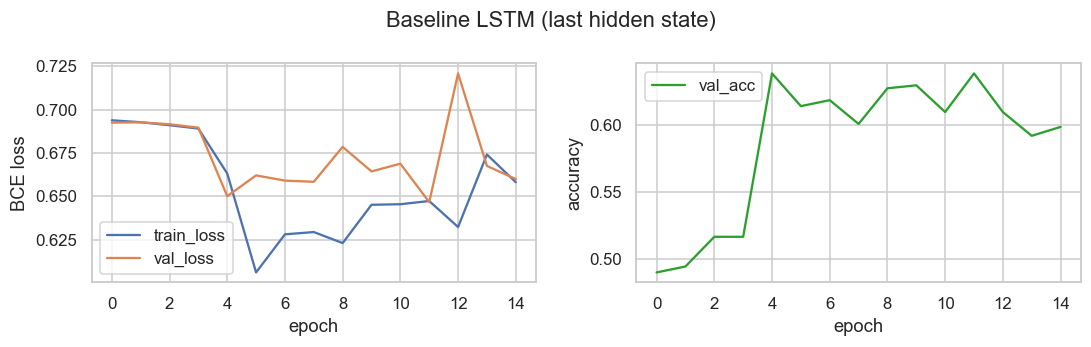

In [45]:
plot_history(hist_base, "Baseline LSTM (last hidden state)")

In [46]:
acc_base = evaluate(model_base, X_te, y_test_tensor)
print(f"Baseline test accuracy: {acc_base:.3f}")

Baseline test accuracy: 0.602


> 🔎 Look at the two loss curves: the training loss keeps falling while the validation loss
> turns upward. That is textbook **overfitting** — with 2 100 short reviews it is unavoidable.
> This is exactly why we restore the best checkpoint.

## The same model + attention

One difference: instead of `h_n[-1]` we pool **all** hidden states with our
`AdditiveAttention` — **and we pass the mask**, so that `<pad>` positions get weight 0.

`mask = (x != PAD_ID)` is a boolean tensor of shape `(batch, time)`: `True` = real word.

In [47]:
class AttentionLSTM(nn.Module):
    def __init__(self, vocab_size, emb_dim=EMB_DIM, hidden_size=HID_DIM, attn_units=32):
        super().__init__()
        self.emb       = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        self.lstm      = nn.LSTM(emb_dim, hidden_size, batch_first=True)
        self.attention = AdditiveAttention(hidden_size, attn_units)
        self.drop      = nn.Dropout(0.3)
        self.head      = nn.Linear(hidden_size, 1)

    def forward(self, x):
        mask = x != PAD_ID                        # (batch, time): True = real token
        H, _ = self.lstm(self.emb(x))             # all hidden states
        context, weights = self.attention(H, mask)
        return self.head(self.drop(context)), weights

In [48]:
torch.manual_seed(SEED)
model_attn = AttentionLSTM(len(itos)).to(device)
torchinfo.summary(model_attn, input_data=X_tr[:32].to(device))

Layer (type:depth-idx)                   Output Shape              Param #
AttentionLSTM                            [32, 1]                   --
├─Embedding: 1-1                         [32, 32, 64]              192,000
├─LSTM: 1-2                              [32, 32, 64]              33,280
├─AdditiveAttention: 1-3                 [32, 64]                  --
│    └─Linear: 2-1                       [32, 32, 32]              2,080
│    └─Linear: 2-2                       [32, 32, 1]               32
├─Dropout: 1-4                           [32, 64]                  --
├─Linear: 1-5                            [32, 1]                   65
Total params: 227,457
Trainable params: 227,457
Non-trainable params: 0
Total mult-adds (M): 40.29
Input size (MB): 0.01
Forward/backward pass size (MB): 1.32
Params size (MB): 0.91
Estimated Total Size (MB): 2.24

> 💡 Compare the parameter counts of the two models. The attention layer adds only about
> **2 000** parameters out of roughly 220 000 — under **1 %**. Attention is **cheap**. 💰

In [49]:
hist_attn = train_classifier(model_attn, epochs=15, returns_weights=True)

epoch  1 | train 0.6821 | val 0.6676 | val acc 0.616
epoch  2 | train 0.6087 | val 0.6066 | val acc 0.667
epoch  3 | train 0.5079 | val 0.5996 | val acc 0.687
epoch  4 | train 0.4235 | val 0.6292 | val acc 0.703
epoch  5 | train 0.3412 | val 0.6422 | val acc 0.705
epoch  6 | train 0.2636 | val 0.7156 | val acc 0.716
epoch  7 | train 0.2153 | val 0.6921 | val acc 0.736
epoch  8 | train 0.1646 | val 0.7801 | val acc 0.727
epoch  9 | train 0.1227 | val 0.9126 | val acc 0.718
epoch 10 | train 0.1404 | val 0.9018 | val acc 0.747
epoch 11 | train 0.0976 | val 0.8420 | val acc 0.716
epoch 12 | train 0.0700 | val 0.9364 | val acc 0.707
epoch 13 | train 0.0544 | val 1.0016 | val acc 0.725
epoch 14 | train 0.0449 | val 1.0968 | val acc 0.734
epoch 15 | train 0.0386 | val 1.1427 | val acc 0.741

Best validation loss: 0.5996 - these weights were restored.


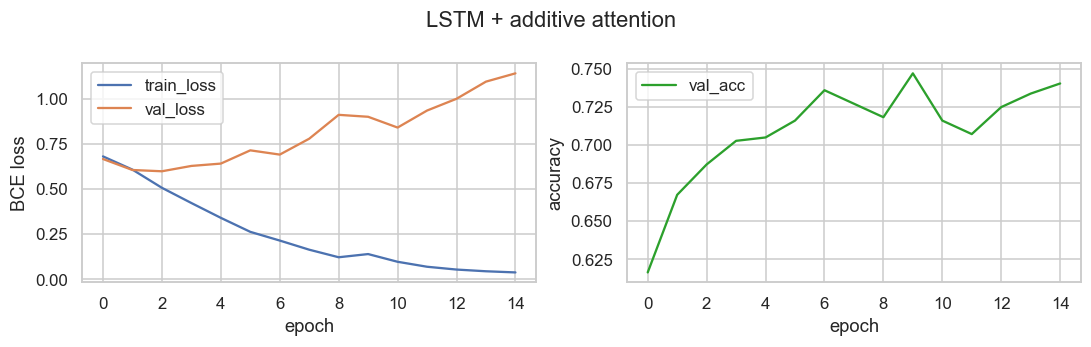

In [50]:
plot_history(hist_attn, "LSTM + additive attention")

In [52]:
acc_attn = evaluate(model_attn, X_te, y_test_tensor, returns_weights=True)

results = pd.DataFrame({
    "model": ["Baseline (last hidden state)", "Attention (weighted sum)"],
    "params": [sum(p.numel() for p in model_base.parameters()),
               sum(p.numel() for p in model_attn.parameters())],
    "test accuracy": [acc_base, acc_attn],
})
results

,model,params,test accuracy
0,Baseline (last hidden state),225345,0.602222
1,Attention (weighted sum),227457,0.746667


## Which words did the model look at? 🔍

The weights $\alpha$ are a distribution over the words of the review. Let's paint them.

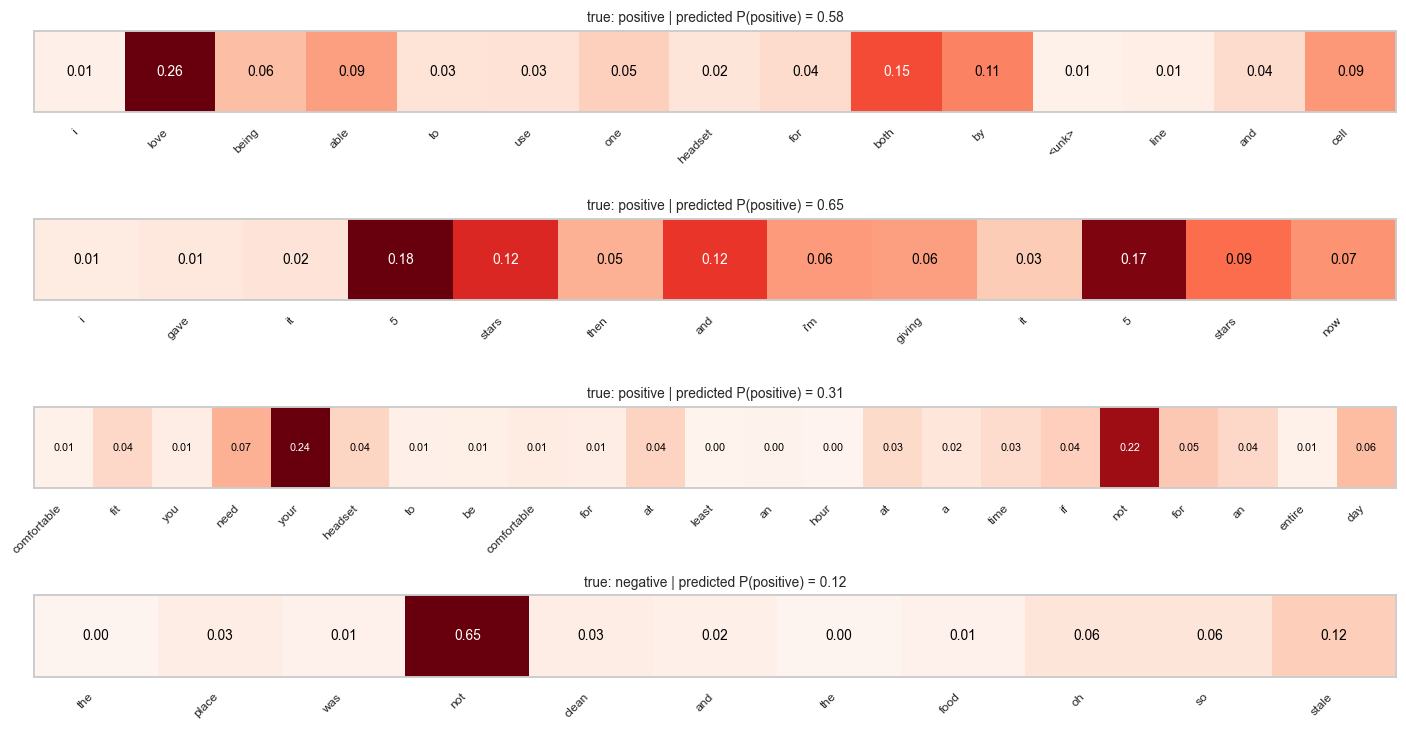

In [56]:
def show_attention(model, X_source, y_source, n=4):
    '''Plot the attention weights over the words of n reviews.'''
    model.eval()
    with torch.no_grad():
        logits, weights = model(X_source[:n].to(device))
    probs = torch.sigmoid(logits).cpu().squeeze(-1)
    weights = weights.cpu()

    fig, axes = plt.subplots(n, 1, figsize=(13, 1.7 * n))
    for i, ax in enumerate(np.atleast_1d(axes)):
        ids = X_source[i].tolist()
        n_tok = sum(1 for t in ids if t != PAD_ID)
        toks = [itos[t] for t in ids[:n_tok]]
        w = weights[i, :n_tok].numpy()
        vmax = max(w.max(), 1e-6)

        ax.imshow(w[None, :], cmap="Reds", aspect="auto", vmin=0, vmax=vmax)

        # --- the numbers inside the cells ---
        fontsize = 9 if n_tok <= 16 else (7 if n_tok <= 24 else 6)
        for k, value in enumerate(w):
            ax.text(k, 0, f"{value:.2f}", ha="center", va="center", fontsize=fontsize,
                    color="white" if value > 0.55 * vmax else "black")

        ax.set_xticks(range(n_tok))
        ax.set_xticklabels(toks, rotation=45, ha="right", fontsize=8)
        ax.set_yticks([])
        ax.grid(False)
        truth = "positive" if y_source[i].item() == 1 else "negative"
        ax.set_title(f"true: {truth} | predicted P(positive) = {probs[i]:.2f}", fontsize=9)

    plt.tight_layout()
    plt.show()

show_attention(model_attn, X_te, y_test_tensor, n=4)

In [58]:
# The same thing as plain text: the three strongest words per review
model_attn.eval()
with torch.no_grad():
    logits, weights = model_attn(X_te[:8].to(device))

for i in range(8):
    ids = X_te[i].tolist()
    n_tok = sum(1 for t in ids if t != PAD_ID)
    toks = [itos[t] for t in ids[:n_tok]]
    w = weights[i, :n_tok].cpu().numpy()
    top3 = set(np.argsort(-w)[:3].tolist())
    marked = " ".join(f"[{t}]" if k in top3 else t for k, t in enumerate(toks))
    print(f"P(pos)={torch.sigmoid(logits[i]).item():.2f} | true={y_test[i]} | {marked}\n")

P(pos)=0.58 | true=1 | i [love] being able to use one headset for [both] [by] <unk> line and cell

P(pos)=0.65 | true=1 | i gave it [5] [stars] then and i'm giving it [5] stars now

P(pos)=0.31 | true=1 | comfortable fit you [need] [your] headset to be comfortable for at least an hour at a time if [not] for an entire day

P(pos)=0.12 | true=0 | the place was [not] clean and the food [oh] so [stale]

P(pos)=0.84 | true=1 | i love the look and [feel] [of] [samsung] <unk>

P(pos)=0.34 | true=0 | he can bore you to <unk> and <unk> the <unk> of a [movie] <unk> [than] [anyone] else

P(pos)=0.55 | true=1 | [jawbone] era is [awesome] [too]

P(pos)=0.71 | true=1 | [they] [were] <unk> <unk> and [delicious]



> 💡 The words in brackets are the top-3 by attention weight. You should see sentiment-carrying
> words like *great, love, delicious, not, worst, bland* — **the model was never told which
> words are important**. It learned that from 2 100 labelled sentences alone. 🤯
>

## ⚠️ Why the mask really matters

Remember the question about `<pad>`? Time to answer it experimentally.

We take the **trained** attention layer and run it **twice** on the same hidden states —
once with the mask, once without.

In [59]:
sample = X_te[:200].to(device)
lengths = (sample != PAD_ID).sum(dim=1)

model_attn.eval()
with torch.no_grad():
    H, _ = model_attn.lstm(model_attn.emb(sample))
    _, w_masked   = model_attn.attention(H, mask=(sample != PAD_ID))
    _, w_unmasked = model_attn.attention(H, mask=None)          # the mask is switched off

pad_mass_masked   = torch.stack([w_masked[i, lengths[i]:].sum()   for i in range(len(sample))])
pad_mass_unmasked = torch.stack([w_unmasked[i, lengths[i]:].sum() for i in range(len(sample))])

print(f"attention mass on <pad> WITH mask   : {pad_mass_masked.mean():.4f}")
print(f"attention mass on <pad> WITHOUT mask: {pad_mass_unmasked.mean():.4f}")

attention mass on <pad> WITH mask   : 0.0000
attention mass on <pad> WITHOUT mask: 0.7289


Without the mask a large share of the attention would be spent on **filler tokens that carry
no information at all** — and the share would depend on how much padding each review happens
to have. 🙃

> 💡 **Rule of thumb:** wherever you use padding, you must use a mask. Every serious attention
> implementation (including the ones in Part 5) takes a mask argument for exactly this reason.

# 5. Modern attention ⚡


Modern architectures generalise this. **Every position asks its own question** about every
other position. That is **self-attention**, and it is the building block of transformers
(next lecture 👀).

### Queries, Keys and Values

The vocabulary comes from information retrieval:

| Symbol | Name | Intuition |
|---|---|---|
| $Q$ | **Query** | what am I looking for? |
| $K$ | **Key** | what do I offer? |
| $V$ | **Value** | what do I hand over when chosen? |

Scores are now a plain **dot product** between queries and keys — no small network needed:

$$\text{Attention}(Q,K,V) \;=\; \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V$$

### Why divide by $\sqrt{d_k}$? 🤔

The dot product of two $d_k$-dimensional random vectors has variance proportional to $d_k$.
For large $d_k$ the scores become huge, softmax saturates into a near one-hot vector, and the
gradients vanish. Dividing by $\sqrt{d_k}$ keeps the scores in a healthy range — hence the name
**scaled** dot-product attention.

Note the shape of the result: for $T$ positions the softmax argument is a $T \times T$ matrix —
**every position attends to every position**.

In [60]:
torch.manual_seed(SEED)

B, T, D = 1, 6, 8          # batch, time steps, dimension
Q = torch.randn(B, T, D)
K = torch.randn(B, T, D)
V = torch.randn(B, T, D)

scores = (Q @ K.transpose(-2, -1)) / (D ** 0.5)   # (B, T, T)
A = torch.softmax(scores, dim=-1)                 # every ROW sums to 1
out_manual = A @ V                                # (B, T, D)

print("attention matrix:", A.shape, "| output:", out_manual.shape)
print("row sums:", A.sum(dim=-1))

attention matrix: torch.Size([1, 6, 6]) | output: torch.Size([1, 6, 8])
row sums: tensor([[1., 1., 1., 1., 1., 1.]])


PyTorch ships the same operation as a highly optimised built-in function
(**`F.scaled_dot_product_attention`**, which can dispatch to FlashAttention on a GPU).
Let's verify that our four lines compute exactly the same thing. ✅

In [61]:
out_builtin = F.scaled_dot_product_attention(Q, K, V)

print("identical results:", torch.allclose(out_manual, out_builtin, atol=1e-6))
print("max difference   :", (out_manual - out_builtin).abs().max().item())

identical results: True
max difference   : 2.384185791015625e-07


### Self-attention on a real sentence

**Self-attention** simply means $Q = K = V = X$ — the sequence asks questions about itself.

Below we take the **trained word embeddings** from our sentiment model and let one review
attend to itself. Bright cells mean "these two words are related in the learned embedding space".

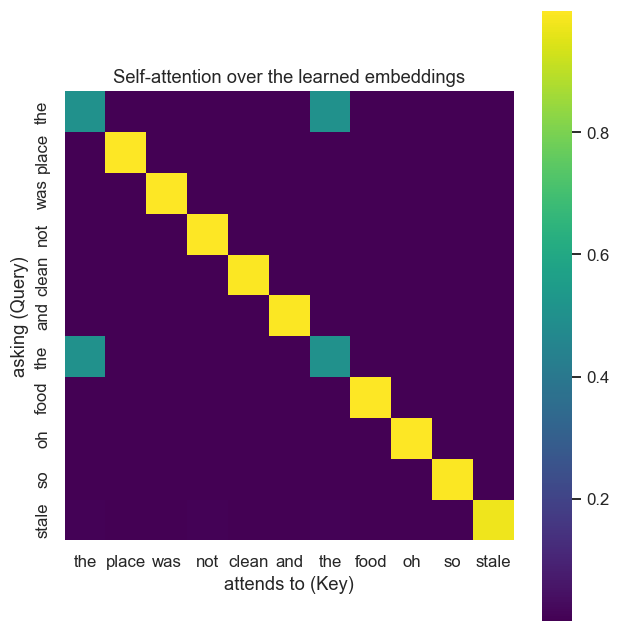

In [62]:
review_ids = X_te[3]
n_tok = int((review_ids != PAD_ID).sum())
tok_labels = [itos[i] for i in review_ids[:n_tok].tolist()]

with torch.no_grad():
    X_emb = model_attn.emb(review_ids[:n_tok].to(device)).unsqueeze(0)   # (1, n_tok, EMB_DIM)
    self_scores = (X_emb @ X_emb.transpose(-2, -1)) / (EMB_DIM ** 0.5)
    A_self = torch.softmax(self_scores, dim=-1)[0].cpu()

plt.figure(figsize=(min(1 + 0.45 * n_tok, 12), min(1 + 0.45 * n_tok, 12)))
sns.heatmap(A_self, xticklabels=tok_labels, yticklabels=tok_labels, cmap="viridis", square=True)
plt.xlabel("attends to (Key)"); plt.ylabel("asking (Query)")
plt.title("Self-attention over the learned embeddings")
plt.tight_layout(); plt.show()

### Masks, take two 🎭

Two masks appear everywhere in modern models:

- **padding mask** — the one we already used: ignore `<pad>` positions,
- **causal (look-ahead) mask** — a position may only attend to itself and to the **past**.
  This is what makes a language model unable to cheat by peeking at the next word.

Both are implemented the same way: set the forbidden scores to $-\infty$ before the softmax.

In [63]:
causal = torch.tril(torch.ones(T, T, dtype=torch.bool))     # lower triangle = allowed

scores = (Q @ K.transpose(-2, -1)) / (D ** 0.5)             # the same scores as above
masked_scores = scores.masked_fill(~causal, float("-inf"))  # the future gets -inf
A_causal = torch.softmax(masked_scores, dim=-1)

print(A_causal[0].round(decimals=2))
print("\nsame as the built-in version:",
      torch.allclose(A_causal @ V,
                     F.scaled_dot_product_attention(Q, K, V, is_causal=True), atol=1e-6))

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2800, 0.7200, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1400, 0.3800, 0.4900, 0.0000, 0.0000, 0.0000],
        [0.0500, 0.1000, 0.7400, 0.1100, 0.0000, 0.0000],
        [0.3700, 0.2100, 0.0500, 0.2200, 0.1500, 0.0000],
        [0.2900, 0.5400, 0.0100, 0.0900, 0.0500, 0.0200]])

same as the built-in version: True


Read the printed matrix: the first row can only use position 0, the second row positions 0–1,
and so on. The upper triangle is exactly zero. 🔺

### Multi-head attention 🧠🧠🧠

One attention distribution can only express **one kind of relationship**. Multi-head attention
runs $h$ attention operations **in parallel** on different learned projections of the same
input, then concatenates the results. In language models different heads specialise —
one tracks syntax, another tracks long-range references, and so on.

PyTorch gives us **`nn.MultiheadAttention`** ready to use.

In [64]:
mha = nn.MultiheadAttention(embed_dim=EMB_DIM, num_heads=4, batch_first=True).to(device)

batch = X_te[:2].to(device)
pad_mask = (batch == PAD_ID)          # NOTE: here True means "ignore this position"!

with torch.no_grad():
    x = model_attn.emb(batch)
    out, attn_w = mha(x, x, x, key_padding_mask=pad_mask,
                      need_weights=True, average_attn_weights=True)

print("output       :", out.shape)          # (batch, time, embed_dim)
print("weights (avg):", attn_w.shape)       # (batch, time, time)

with torch.no_grad():
    _, attn_per_head = mha(x, x, x, key_padding_mask=pad_mask,
                           need_weights=True, average_attn_weights=False)
print("weights per head:", attn_per_head.shape)   # (batch, heads, time, time)

output       : torch.Size([2, 32, 64])
weights (avg): torch.Size([2, 32, 32])
weights per head: torch.Size([2, 4, 32, 32])


> ⚠️ **A classic trap:** in our `AdditiveAttention` the mask uses `True` for **keep**, while
> `nn.MultiheadAttention` expects `True` for **ignore**. Always check the convention of the
> layer you are using — an inverted mask trains silently and gives nonsense. 🙃

# 6. Activities ✏️

## Activity 1 — Dot-product instead of additive scoring 🔁

Our `AdditiveAttention` scores a position with a small network, $e_t = v^\top \tanh(W h_t)$.
The cheaper alternative is a **plain dot product with a single learnable vector**:
$e_t = h_t \cdot w$ — exactly what we did by hand in Part 2.

**What to do**

1. Write a new module `DotProductAttention(nn.Module)`. In `__init__` create a single
   learnable vector, e.g. `self.w = nn.Parameter(torch.randn(hidden_size) * 0.1)`
   (or equivalently a `nn.Linear(hidden_size, 1, bias=False)`).
2. In `forward(H, mask=None)` compute the scores as `H @ self.w`, apply the same
   `masked_fill` + `softmax` + weighted sum, and return `(context, weights)` — keep the
   interface identical, so the module is a drop-in replacement.
3. Build a second `AttentionLSTM` that uses it (the easiest way is to instantiate the model
   and then overwrite `model.attention = DotProductAttention(HID_DIM).to(device)`),
   train it with `train_classifier(..., returns_weights=True)` and evaluate it on the test set.
4. Compare with the additive version: **test accuracy**, **number of parameters**
   (`sum(p.numel() for p in m.parameters())`) and **training time**.

## Activity 2 — Bidirectional LSTM 🔄

A normal LSTM reads left to right, so the hidden state at position $t$ knows nothing about the
words that follow. `nn.LSTM(..., bidirectional=True)` runs a second LSTM backwards and
**concatenates** both hidden states.

**What to do**

1. Create a variant of `AttentionLSTM` with `bidirectional=True` in the LSTM.
2. ⚠️ The hidden states are now **twice as wide**, so the attention layer and the output layer
   must be built with `hidden_size * 2`. Fix the dimensions — a shape error here is the point
   of the exercise.
3. Train it and compare test accuracy with the one-directional model.
4. Print the parameter count of both models.

## Activity 3 — Attention without a mask 🐛

We measured that a trained layer would put a lot of weight on `<pad>` if the mask were removed.
Now train a model that **never had a mask**.

**What to do**

1. Copy `AttentionLSTM` and delete the mask (pass `mask=None` into the attention layer).
2. Train it with the same settings and evaluate it on the test set.
3. Use `show_attention` (or your own plot) on a few **short** reviews — short reviews have the
   most padding, so the effect is the strongest.
4. Measure the average attention mass that lands on `<pad>` positions, the same way we did above.

## Activity 4 — Multi-head attention 🧠🧠 
Replace our single-question attention with real multi-head self-attention.

**What to do**

1. Build a model: `Embedding → LSTM(return all states) → nn.MultiheadAttention(self-attention)
   → mean over the real tokens → Linear`.
   - use `mha(H, H, H, key_padding_mask=(x == PAD_ID))` — remember the **inverted** mask
     convention,
   - when averaging over time, exclude the padded positions
     (multiply by the mask and divide by the number of real tokens).
2. Train it with `num_heads = 1`, `2` and `4` and compare the test accuracy.
3. Extract the per-head attention matrices (`average_attn_weights=False`) for one review and
   plot them side by side as heatmaps.
